In [1]:
from anemone.forwards import *
import matplotlib.pyplot as plt
import numpy as np

In [2]:
from anemone.physics import rte_raiche1999 as rte


In [3]:
from anemone.physics import rte_halfspace

In [7]:
# --- 1D Lamontagne spline definitions ---
S1 = lambda x: 1 - (9/4)*x**2 * (1 - 2/9*x*(1 + 5/2*x*(1 - 2/5*x)))
S2 = lambda x: -0.5*x*(1 - 11/6*x*(1 - 2/11*x*(1 + 5/2*x*(1 - 2/5*x))))

def lamontagne(x):
    phi = np.zeros_like(x)
    xm2m1 = (-2 <= x) & (x < -1)
    xm1m0 = (-1 <= x) & (x < 0)
    x0p1  = (0 <= x) & (x <= 1)
    x1p2  = (1 < x) & (x <= 2)
    phi[xm2m1] = S2(-x[xm2m1]-1)
    phi[xm1m0] = S1(-x[xm1m0])
    phi[x0p1]  = S1(x[x0p1])
    phi[x1p2]  = S2(x[x1p2]-1)
    return phi

# --- 2D scattered interpolation matrix builder ---
def intMat_2d_scattered(x_in, y_in, x_out, y_out):
    """
    Build 2D Lamontagne spline interpolation matrix between scattered points.
    All inputs should be 1D torch tensors (x_in, y_in, x_out, y_out).
    """
    logx_in, logy_in = np.log(x_in), np.log(y_in)
    logx_out, logy_out = np.log(x_out), np.log(y_out)

    dx = logx_in[1]-logx_in[0]
    dy = logy_in[1]-logy_in[0]


    # pairwise differences
    Δx = (logx_out[:, None] - logx_in[None, :]) / dx
    Δy = (logy_out[:, None] - logy_in[None, :]) / dy

    # Evaluate separable 2D Lamontagne basis
    Wx = lamontagne(Δx)
    Wy = lamontagne(Δy)
    
    # print(Wx.shape, Wy.shape)
    W = Wx[:, :, None] * Wy[:, None, :]
    W = np.nan_to_num(W)
    return W.reshape(len(x_out), -1)  # shape [n_out, n_in]


def interp2d_lamontagne_scattered(x_in, y_in, f_in, x_out, y_out):
    """
    Perform 2D Lamontagne spline interpolation between scattered points.
    """
    M = intMat_2d_scattered(x_in, y_in, x_out, y_out)
    print(M.shape)
    f_out = M @ f_in
    return f_out

In [121]:
def make_H2t(t2t, geomz, omega, lmb, tolerance=1e-6, sigma_ref=0.1):
    # if t_indices is None:
    t_indices = np.arange(t2t.shape[0])

    t1 = (t2t[0, :, None]*geomz.real[None, :]).numpy()
    full_mask = np.zeros_like(t1, dtype=bool)

    rte_ref = rte_halfspace(torch.tensor(sigma_ref), omega[:,None], lmb[None,:]).squeeze().cpu().numpy()

    for i in t_indices:
        t1 = (t2t[i, :, None]*geomz.real[None, :]).numpy()*rte_ref
        t1_shape = t1.shape
        t1sort = np.abs(t1).flatten()
        # indices = np.arange(len(t1sort))

        sort_idx = np.argsort(t1sort)
        t1sort = t1sort[sort_idx]
        t1cumsum = np.cumsum(t1sort)
        t1cumsum /= t1cumsum[-1]
        idx = np.searchsorted(t1cumsum, tolerance)#-1

        mask = np.zeros_like(t1sort, dtype=bool)
        mask[idx:] = True


        inv_sort = np.argsort(sort_idx)
        mask = mask[inv_sort].reshape(t1_shape)
        full_mask += mask
    
    omega_i = np.arange(omega.squeeze().shape[0])
    lamda_i = np.arange(lmb.squeeze().shape[0])
    omega_i, lamda_i = np.meshgrid(omega_i, lamda_i, indexing='ij')

    omega_i = omega_i[full_mask]
    lamda_i = lamda_i[full_mask]
    # print(omega_i.min(), omega_i.max(), lamda_i.min(), lamda_i.max())
    print('n omegas: ', omega_i.max()-omega_i.min())
    print('n lambdas: ', lamda_i.max()-lamda_i.min())

    # full_mask[:,:] = False
    # full_mask[int(omega_i.min()):int(omega_i.max()), int(lamda_i.min()):int(lamda_i.max())] = True

    H2t = np.zeros(t2t.shape[:1]+(full_mask.sum(),), dtype=complex)

    for i in range(t2t.shape[0]):
        t1 = (t2t[i, :, None]*geomz.real[None, :]).numpy()
        H2t[i] = t1[full_mask].flatten()

    H2tweight = np.abs(H2t).sum(0)#.numpy()

    idx_H2t = np.argsort(H2tweight)[::-1]
    H2t = H2t[:, idx_H2t]

    Omega,Lambda = np.meshgrid(omega.squeeze().cpu().numpy(), lmb.squeeze().cpu().numpy(), indexing='ij')
    Omega = Omega[full_mask]
    Lambda = Lambda[full_mask]

    o,l = Omega[idx_H2t].real, Lambda[idx_H2t].real
    og = np.logspace(np.log10(o.min()), np.log10(o.max()), 35)
    lg = np.logspace(np.log10(l.min()), np.log10(l.max()), 35)

    omega_grid, lmb_grid = np.meshgrid(og, lg, indexing='ij')
    wt = intMat_2d_scattered(og, lg, o, l)
    return torch.tensor(H2t@wt),  torch.tensor(omega_grid.flatten())+0j, torch.tensor(lmb_grid.flatten())+0j

class ForwardFlow(Forward):
    geomz = None
    t2t   = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=1e-7):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance, precalc=False)
        self.t2t = None
        self.setup()        
        


    def setup(self):
        self.rho   = 40*torch.ones(2)[:, None, None] + 0j
        self.thick = 20*torch.ones(1)[:, None, None] + 0j

        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]          
                self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz)*self.lmb / c.fourpi
                intg = rte(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte
                return intg.squeeze()
            hkl1 = Hankel(wvlngth_integrand, 1, device=self.device)
            def geomz_r(r):
                return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
            Hr, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
            
            self.geomz *= torch.exp(-self.lmb*self.sfield_dz)*self.lmb / c.fourpi

            return Hr.squeeze()
        
        if self.t2t is None:
            self.cbft=invFourier(frq_integrand, device=self.device)
            def t2t_func(t_in):
                if self.t_gatewidth is not None:
                    waveform_matrix = wv_to_t(t_in, t_in, waveform=self.waveform)
                    gate_matrix = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                    return gate_matrix @ waveform_matrix
                else:
                    return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax*100.)
            scalar = self.times**(5/2)
            self.scalar = scalar/scalar.min()
            # self.t2t *= self.scalar[:, None]

            if self.filterfunc is not None:
                self.t2t *= self.filterfunc.omega_filter(self.omega1.squeeze())
            if self.waveform is not None:
                self.t2t /= -1j#*self.omega1.squeeze()
            else:
                self.t2t *= self.omega1.squeeze()

        self.H2t, self.omega, self.lmb = make_H2t(self.t2t, self.geomz, self.omega1, self.lmb, tolerance=self.tolerance)

        self.H2t       = self.H2t.to(self.device).to(torch.cdouble)
        self.H2t      /= torch.sqrt(self.omega)
        self.H2t      /= c.sqrt_twopi
        self.omega    *= c.sqrt_twopi
        self.H2tjac    = self.H2t                                    #[:, :3*len(self.omega)//6]
        self.omegajac  = self.omega                                  #[:3*len(self.omega)//6]
        self.lmbjac    = self.lmb                                    #[:3*len(self.omega)//6]
    
    def forward(self):
        with torch.no_grad():
            # self.sigma = self.rho * self.thick
            cRTE = rte(self.sigma, self.thick, self.omega, self.lmb).squeeze()
            return torch.einsum('ik,...k->i...', self.H2t, cRTE)

    def jacobian(self):
        dRTE = drte_dsigma(self.sigma, self.thick, self.omegajac, self.lmbjac).squeeze()
        Gr = torch.einsum('ik,...k->...i', dRTE.real, self.H2tjac.real) - torch.einsum('ik,jk->ij', dRTE.imag, self.H2tjac.imag)
        return Gr

In [129]:
#rho, thick = torch.tensor([40, 80, 20]), torch.ones(2)*20
rho, thick = torch.ones(30)*40, torch.ones(29)*10
rho, thick = torch.ones(3)*40, torch.ones(2)*20

fwr1 = ForwardFlow.example(times=torch.logspace(-5,-3, 30), tolerance=1e-6)
dbdt1 = fwr1(rho, thick)

# fwr2 = ForwardFlow2.example(times=torch.logspace(-5,-3, 30), tolerance=1e-6)
# dbdt2 = fwr2(rho, thick)
# rte1 = fwr2.cRTE*1.

fwr0 = BaseForward.example(times=torch.logspace(-5,-3, 30))
dbdt0 = fwr0(rho, thick)

print(len(fwr1.omega))

n omegas:  93
n lambdas:  48
1225


In [130]:
rho = torch.ones(10)
thick = torch.ones(9)*20

In [131]:
rhos = rho[:, None]*torch.logspace(0, 3, 15)[None, :]
dbdt0 = fwr0(rhos, thick)
dbdt1 = fwr1(rhos, thick)

In [132]:
%%timeit
dbdt1 = fwr1(rhos, thick)

13.2 ms ± 269 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


C:\Users\au646858\AppData\Local\Temp\ipykernel_28064\1457055266.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[0].loglog(fwr0.times, np.abs(dbdt0.real).T, 'k-', label='dbdt0')
C:\Users\au646858\AppData\Local\Temp\ipykernel_28064\1457055266.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[0].loglog(fwr1.times, np.abs(dbdt1.real), '--', label='dbdt1')
C:\Users\au646858\AppData\Local\Temp\ipykernel_28064\1457055266.py:6: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rel_err = 100*np.abs(dbdt1.real.T-dbdt0.real)/np.abs(dbdt0.real)


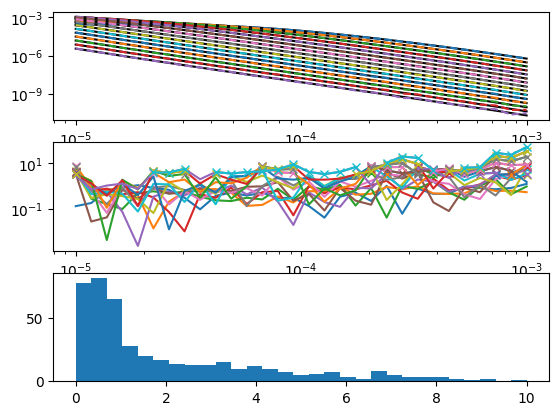

In [133]:
fig,axs = plt.subplots(3,1)

axs[0].loglog(fwr0.times, np.abs(dbdt0.real).T, 'k-', label='dbdt0')
axs[0].loglog(fwr1.times, np.abs(dbdt1.real), '--', label='dbdt1')

rel_err = 100*np.abs(dbdt1.real.T-dbdt0.real)/np.abs(dbdt0.real)
axs[1].loglog(fwr0.times, rel_err.T, '-')
axs[2].hist(rel_err.flatten(), bins=np.linspace(0, 10, 30))

rel_err[rel_err<3] = np.nan
axs[1].loglog(fwr0.times, rel_err.T, 'x-')

In [22]:
rho = torch.ones(10)
thick = torch.ones(9)*20

rhos = rho[:, None]*np.logspace(0, 2, 100)[None, :]

C:\Users\au646858\AppData\Local\Temp\ipykernel_28064\1563106251.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rhos = rho[:, None]*np.logspace(0, 2, 100)[None, :]


In [15]:
%%timeit
dbdt2 = fwr2(rhos, thick)

151 ms ± 13.1 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [24]:
from time import perf_counter_ns as timer
n_mods = [1, 10, 20, 50, 100, 200, 500, 1000]
calc_time = []
batch=100
for n_mod in n_mods:
    # if n_mod < 100:
    #     repeat = 10
    # elif n_mod < 1001:
    #     repeat = 3
    # else:
    #     repeat = 1
    repeat = 10
    rhos = rho[:, None]*np.logspace(0, 3, n_mod)[None, :]

    bt = timer()
    for _ in range(repeat):
        i = 0
        while (i+2)*batch<n_mod:
            dbdt2 = fwr2(rhos[:, i*batch:(i+1)*batch], thick)
            i += 1
        dbdt2 = fwr2(rhos[:, i*batch:], thick)
    et = timer()
    calc_time.append((et-bt)/repeat*1e-6)
    print(n_mod, (et-bt)/repeat*1e-6/n_mod)

C:\Users\au646858\AppData\Local\Temp\ipykernel_8012\738278162.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rhos = rho[:, None]*np.logspace(0, 3, n_mod)[None, :]


1 7.36353
10 2.633352
20 1.948783
50 2.1658475999999998
100 2.9027309
200 2.885444
500 2.9923897
1000 3.13048213


In [25]:
n_mods = np.array(n_mods)
calc_time = np.array(calc_time)

(1, 100)

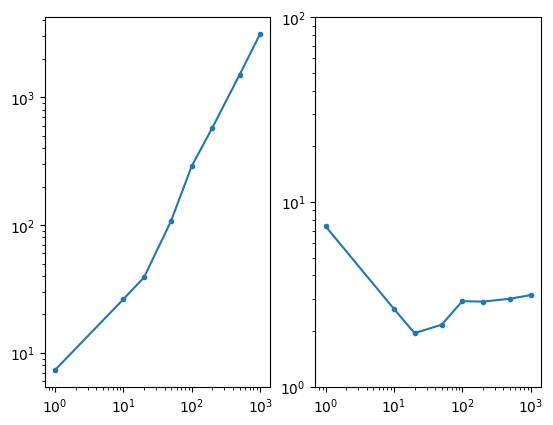

In [26]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(n_mods, calc_time, '.-')
axs[1].loglog(n_mods, calc_time/n_mods, '.-')
axs[1].set_ylim(1, 100)

C:\Users\au646858\AppData\Local\Temp\ipykernel_28064\3247194013.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rhos = rho[:, None]*np.logspace(0, 2, 100)[None, :]
C:\Users\au646858\AppData\Local\Temp\ipykernel_28064\3247194013.py:8: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.loglog(fwr2.times, np.abs(dbdt2), label='max diff');


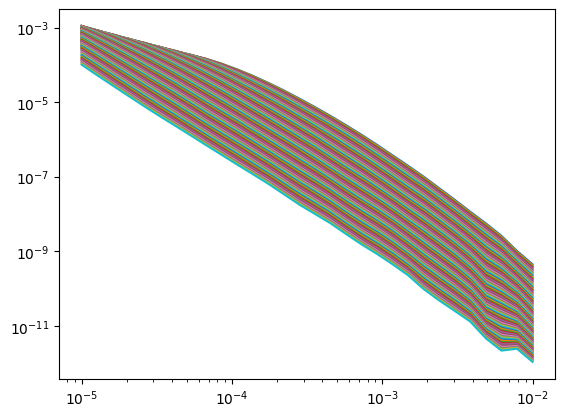

In [16]:
rho = torch.ones(10)
thick = torch.ones(9)*20

rhos = rho[:, None]*np.logspace(0, 2, 100)[None, :]

dbdt2 = fwr2(rhos, thick)
plt.figure()
plt.loglog(fwr2.times, np.abs(dbdt2), label='max diff');

C:\Users\au646858\AppData\Local\Temp\ipykernel_8012\3909777505.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[1].loglog(fwr2.times, np.abs(dbdt2.real), '-', label=f'rho={rho}')


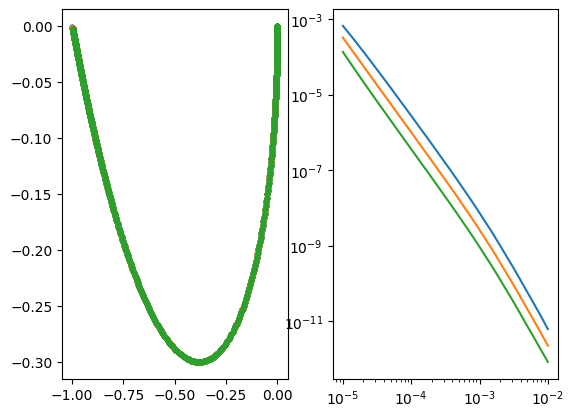

In [17]:
fig,axs =plt.subplots(1,2)

for rho in [20, 40, 80]:
    rhos = torch.ones(3)*rho
    dbdt2 = fwr2(rhos, thick)
    axs[0].plot(fwr2.cRTE.real, fwr2.cRTE.imag, '.', label=f'rho={rho}')
    axs[1].loglog(fwr2.times, np.abs(dbdt2.real), '-', label=f'rho={rho}')

In [ ]:
print(len(fwr2.omega))
print(len(fwr2.cRTE))

4714
4714


4714
4714


c:\Users\au646858\Documents\repositories\anemone\.venv\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\au646858\Documents\repositories\anemone\.venv\Lib\site-packages\matplotlib\collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


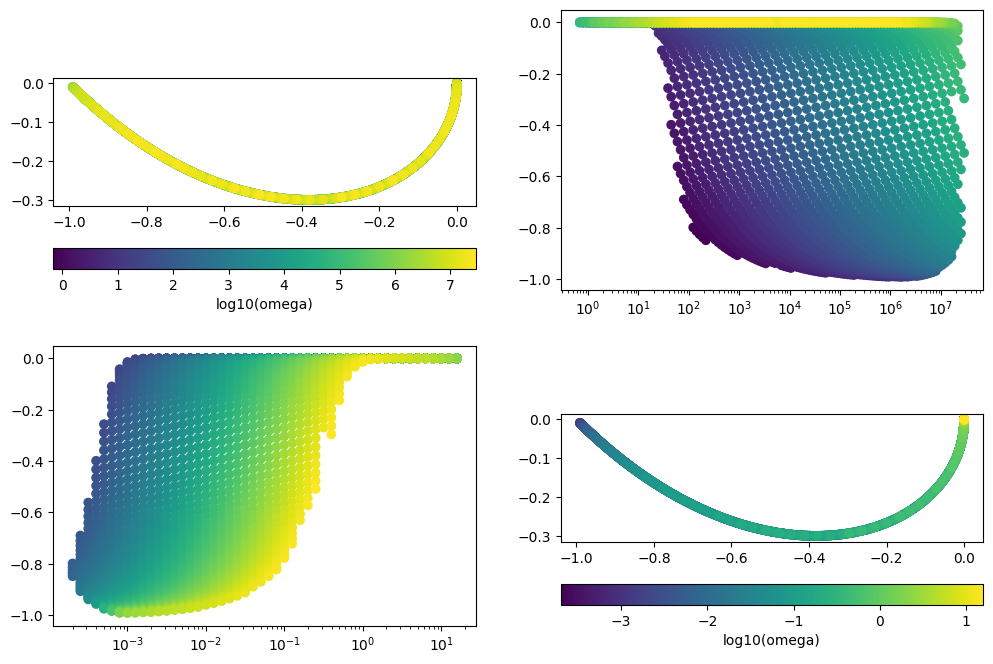

In [ ]:
fig,axs= plt.subplots(2,2, figsize=(12,8))
axs=axs.flatten()

rho, thick = torch.tensor([80,80,80]), torch.ones(2)*20

dbdt2 = fwr2(rho, thick)
s = np.log10(fwr2.omega.real.numpy().astype(float))
idx = np.argsort(s)

print(len(fwr2.omega))
print(len(fwr2.cRTE))

pcm=axs[0].scatter(fwr2.cRTE.real[idx], fwr2.cRTE.imag[idx],  c=s[idx])
axs[0].set_aspect('equal')
fig.colorbar(pcm, ax=axs[0], label='log10(omega)', orientation='horizontal')

axs[2].scatter(fwr2.lmb[idx], fwr2.cRTE.real[idx], c=s[idx])

s = np.log10(fwr2.lmb.real.numpy().astype(float))
idx = np.argsort(s)

axs[1].scatter(fwr2.omega[idx], fwr2.cRTE.real[idx], c=s[idx])
# axs[1].semilogx(fwr2.omega, fwr2.cRTE.imag, '.')

pcm=axs[3].scatter(fwr2.cRTE.real[idx], fwr2.cRTE.imag[idx],  c=s[idx])
axs[3].set_aspect('equal')
fig.colorbar(pcm, ax=axs[3], label='log10(omega)', orientation='horizontal')

axs[1].set_xscale('log')
axs[2].set_xscale('log')
# axs[2].semilogx(fwr2.lmb, fwr2.cRTE.imag, '.')
# plt.plot(rte1.real, rte1.imag, 'k-')

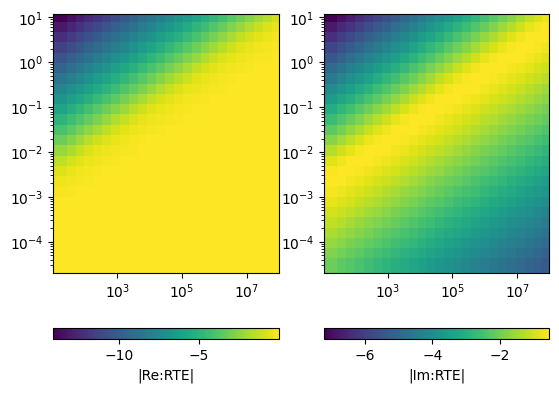

In [30]:
o,l = fwr2.omega.real.numpy(), fwr2.lmb.real.numpy()

omega_grid, lmb_grid = np.meshgrid(np.logspace(np.log10(o.min()), np.log10(o.max()), 25), np.logspace(np.log10(l.min()), np.log10(l.max()), 25), indexing='ij')
omega_grid, lmb_grid = torch.from_numpy(omega_grid).to(fwr2.device), torch.from_numpy(lmb_grid).to(fwr2.device)
rte_grid = rte(1./rho, thick, omega_grid, lmb_grid).squeeze().cpu().numpy()



fig,axs=plt.subplots(1,2)
pcm=axs[0].pcolormesh(omega_grid, lmb_grid, np.log10(np.abs(rte_grid.real)), shading='auto')
plt.colorbar(pcm, label='|Re:RTE|', ax=axs[0], orientation='horizontal')

axs[0].set_xscale('log')
axs[0].set_yscale('log')

pcm=axs[1].pcolormesh(omega_grid, lmb_grid, np.log10(np.abs(rte_grid.imag)), shading='auto')
plt.colorbar(pcm, label='|Im:RTE|', ax=axs[1], orientation='horizontal')

axs[1].set_xscale('log')
axs[1].set_yscale('log')

In [32]:
len(fwr2.omega)
25*25

625

In [ ]:
import torch

# --- 1D Lamontagne spline definitions ---
S1 = lambda x: 1 - (9/4)*x**2 * (1 - 2/9*x*(1 + 5/2*x*(1 - 2/5*x)))
S2 = lambda x: -0.5*x*(1 - 11/6*x*(1 - 2/11*x*(1 + 5/2*x*(1 - 2/5*x))))

def lamontagne(x):
    phi = np.zeros_like(x)
    xm2m1 = (-2 <= x) & (x < -1)
    xm1m0 = (-1 <= x) & (x < 0)
    x0p1  = (0 <= x) & (x <= 1)
    x1p2  = (1 < x) & (x <= 2)
    phi[xm2m1] = S2(-x[xm2m1]-1)
    phi[xm1m0] = S1(-x[xm1m0])
    phi[x0p1]  = S1(x[x0p1])
    phi[x1p2]  = S2(x[x1p2]-1)
    return phi

# --- 2D scattered interpolation matrix builder ---
def intMat_2d_scattered(x_in, y_in, x_out, y_out):
    """
    Build 2D Lamontagne spline interpolation matrix between scattered points.
    All inputs should be 1D torch tensors (x_in, y_in, x_out, y_out).
    """
    logx_in, logy_in = np.log(x_in), np.log(y_in)
    logx_out, logy_out = np.log(x_out), np.log(y_out)

    dx = logx_in[1]-logx_in[0]
    dy = logy_in[1]-logy_in[0]


    # pairwise differences
    Δx = (logx_out[:, None] - logx_in[None, :]) / dx
    Δy = (logy_out[:, None] - logy_in[None, :]) / dy

    # Evaluate separable 2D Lamontagne basis
    Wx = lamontagne(Δx)
    Wy = lamontagne(Δy)
    
    # print(Wx.shape, Wy.shape)
    W = Wx[:, :, None] * Wy[:, None, :]
    W = np.nan_to_num(W)
    return W.reshape(len(x_out), -1)  # shape [n_out, n_in]


def interp2d_lamontagne_scattered(x_in, y_in, f_in, x_out, y_out):
    """
    Perform 2D Lamontagne spline interpolation between scattered points.
    """
    M = intMat_2d_scattered(x_in, y_in, x_out, y_out)
    print(M.shape)
    f_out = M @ f_in
    return f_out

o,l = fwr2.omega.real.numpy(), fwr2.lmb.real.numpy()
og = np.logspace(np.log10(o.min()/1.3), np.log10(o.max()*1.3), 50)
lg = np.logspace(np.log10(l.min()/1.3), np.log10(l.max()*1.3), 50)

omega_grid, lmb_grid = np.meshgrid(og, lg, indexing='ij')
omega_grid, lmb_grid = torch.from_numpy(omega_grid).to(fwr2.device), torch.from_numpy(lmb_grid).to(fwr2.device)

rte_grid = rte(1./rho, thick, omega_grid, lmb_grid).squeeze().cpu().numpy().flatten()
rte_true = rte(1./rho, thick, fwr2.omega, fwr2.lmb).squeeze().cpu().numpy()

wt = intMat_2d_scattered(og, lg, o, l)

rte_int = wt @ rte_grid

fig,axs=plt.subplots(1,2)
axs[0].plot(rte_int.real, rte_int.imag, 'r.', label='interp')
axs[0].plot(rte_true.real, rte_true.imag, 'b.', label='true')
axs[1].plot(100*np.abs(rte_int.real-rte_true.real)/np.abs(rte_true.real), '.', label='rel err')
axs[1].plot(100*np.abs(rte_int.imag-rte_true.imag)/np.abs(rte_true.imag), '.', label='rel err')

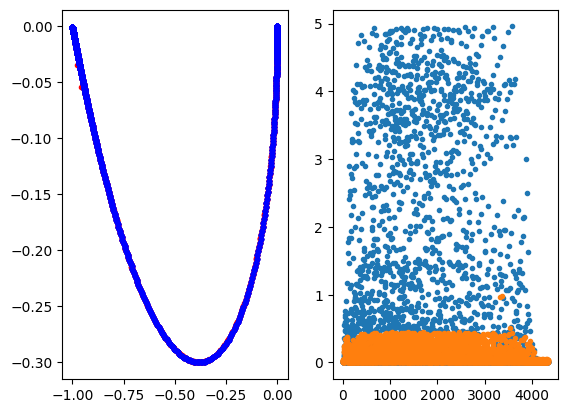

In [ ]:
o,l = fwr2.omega.real.numpy(), fwr2.lmb.real.numpy()
og = np.logspace(np.log10(o.min()/1.3), np.log10(o.max()*1.3), 50)
lg = np.logspace(np.log10(l.min()/1.3), np.log10(l.max()*1.3), 50)

omega_grid, lmb_grid = np.meshgrid(og, lg, indexing='ij')
omega_grid, lmb_grid = torch.from_numpy(omega_grid).to(fwr2.device), torch.from_numpy(lmb_grid).to(fwr2.device)

rte_grid = rte(1./rho, thick, omega_grid, lmb_grid).squeeze().cpu().numpy().flatten()
rte_true = rte(1./rho, thick, fwr2.omega, fwr2.lmb).squeeze().cpu().numpy()

wt = intMat_2d_scattered(og, lg, o, l)

rte_int = wt @ rte_grid

fig,axs=plt.subplots(1,2)
axs[0].plot(rte_int.real, rte_int.imag, 'r.', label='interp')
axs[0].plot(rte_true.real, rte_true.imag, 'b.', label='true')
axs[1].plot(100*np.abs(rte_int.real-rte_true.real)/np.abs(rte_true.real), '.', label='rel err')
axs[1].plot(100*np.abs(rte_int.imag-rte_true.imag)/np.abs(rte_true.imag), '.', label='rel err')

In [43]:
o,l = fwr2.omega.real.numpy(), fwr2.lmb.real.numpy()

omega_grid, lmb_grid = np.meshgrid(np.logspace(np.log10(o.min()), np.log10(o.max()), 25), np.logspace(np.log10(l.min()), np.log10(l.max()), 25), indexing='ij')
omega_grid, lmb_grid = torch.from_numpy(omega_grid).to(fwr2.device), torch.from_numpy(lmb_grid).to(fwr2.device)
rte_grid = rte(1./rho, thick, omega_grid, lmb_grid).squeeze().cpu().numpy()

rte_int = interp2d_lamontagne_scattered(omega_grid.flatten(), lmb_grid.flatten(), rte_grid.real.flatten(), fwr2.omega.real, fwr2.lmb.real)


torch.Size([4341, 625])


C:\Users\au646858\AppData\Local\Temp\ipykernel_8012\246993475.py:50: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  f_out = M @ f_in


In [40]:
rte_int

tensor([0., 0., 0.,  ..., 0., 0., 0.], dtype=torch.float64)

In [41]:
plt.figure()
plt.plot(rte_int.real, rte_int.imag, 'r.', label='interp')

RuntimeError: imag is not implemented for tensors with non-complex dtypes.

<Figure size 640x480 with 0 Axes>

C:\Users\au646858\AppData\Local\Temp\ipykernel_17796\3853780203.py:8: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[2].loglog(fwr2.omega.numpy().real, 100*np.abs(rte_half.real-fwr2.cRTE.real.numpy())/np.abs(fwr2.cRTE.real.numpy()), '.')


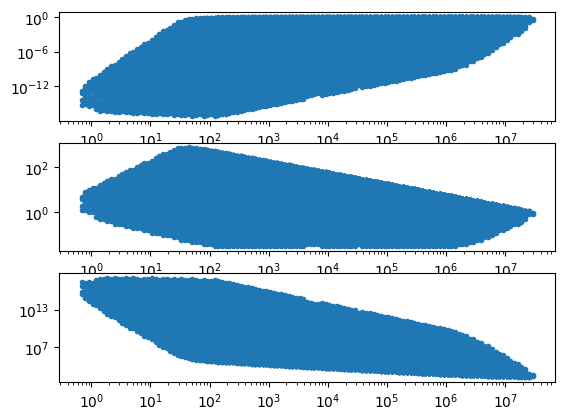

In [ ]:
rho, thick = torch.tensor([80,40,80]), torch.ones(2)*40
dbdt2 = fwr2(rho, thick)
rte_half = rte_halfspace(1./rho[0], fwr2.omega, fwr2.lmb).squeeze()

fig,axs=plt.subplots(3,1)
axs[0].loglog(fwr2.omega.numpy().real, np.abs(fwr2.cRTE.real.numpy()), '.')
axs[1].loglog(fwr2.omega.numpy().real, np.abs(rte_half.real.numpy()), '.')
axs[2].loglog(fwr2.omega.numpy().real, 100*np.abs(rte_half.real-fwr2.cRTE.real.numpy())/np.abs(fwr2.cRTE.real.numpy()), '.')


C:\Users\au646858\AppData\Local\Temp\ipykernel_17796\333291062.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.imshow(np.log10(np.abs(fwr1.H2t)), aspect='auto')


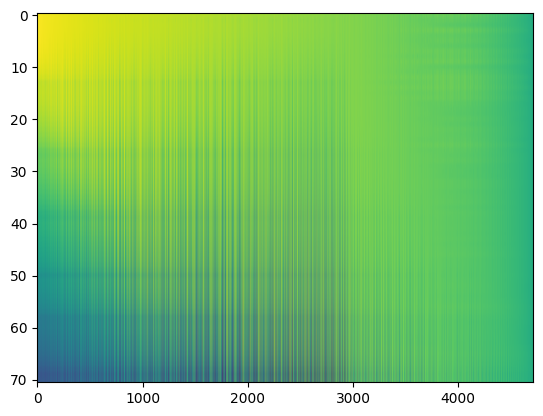

In [ ]:
plt.figure()
plt.imshow(np.log10(np.abs(fwr1.H2t)), aspect='auto')

In [ ]:
fwr1.lmb.shape

torch.Size([4714])

C:\Users\au646858\AppData\Local\Temp\ipykernel_17796\3613680087.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[0].loglog(fwr0.times, np.abs(dbdt0.real), '-', label='dbdt0')
C:\Users\au646858\AppData\Local\Temp\ipykernel_17796\3613680087.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[0].loglog(fwr1.times, np.abs(dbdt1.real), '--', label='dbdt1')
C:\Users\au646858\AppData\Local\Temp\ipykernel_17796\3613680087.py:6: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[1].loglog(fwr0.times, 100*np.abs(dbdt1.real-dbdt0.real)/np.abs(dbdt0.real), '-')


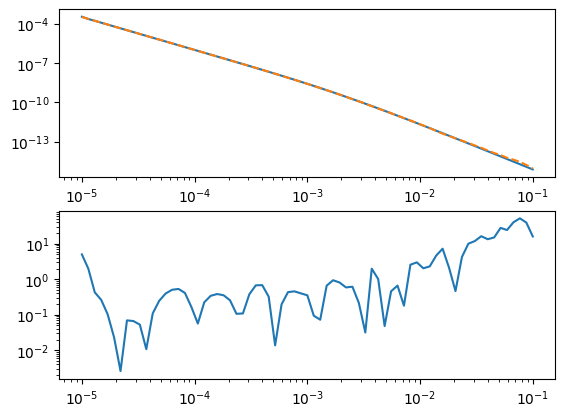

In [ ]:
fig,axs = plt.subplots(2,1)

axs[0].loglog(fwr0.times, np.abs(dbdt0.real), '-', label='dbdt0')
axs[0].loglog(fwr1.times, np.abs(dbdt1.real), '--', label='dbdt1')

axs[1].loglog(fwr0.times, 100*np.abs(dbdt1.real-dbdt0.real)/np.abs(dbdt0.real), '-')

In [ ]:
G1 = fwr1(rho, thick, jac=True)
G0 = fwr0(rho, thick, jac=True)

TypeError: BaseForward.__call__() got an unexpected keyword argument 'jac'

In [ ]:
%%timeit
G1 = fwr1(rho, thick, jac=True)

4.99 ms ± 598 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [ ]:
%%timeit
G0 = fwr0(rho, thick, jac=True)

235 ms ± 23.9 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [ ]:
rho = torch.ones(10)*40
thick = torch.ones(9)*20

C:\Users\au646858\AppData\Local\Temp\ipykernel_17796\1078106055.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[0].imshow(np.log10(np.abs(G0)), aspect='auto')
C:\Users\au646858\AppData\Local\Temp\ipykernel_17796\1078106055.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[1].imshow(np.log10(np.abs(G1)), aspect='auto')


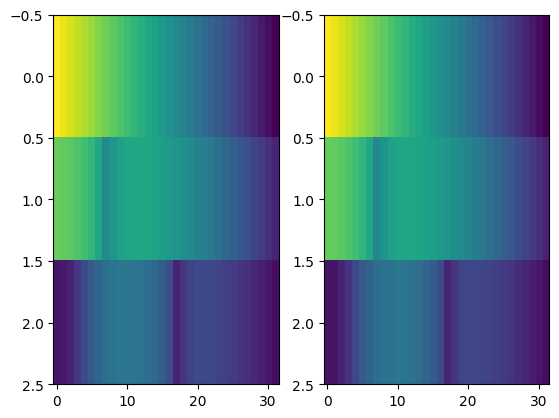

In [ ]:
fig,axs= plt.subplots(1,2)
axs[0].imshow(np.log10(np.abs(G0)), aspect='auto')
axs[1].imshow(np.log10(np.abs(G1)), aspect='auto')

In [ ]:
%%timeit
dbdt0 = fwr0(rho, thick)

105 ms ± 5.37 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [ ]:
%%timeit
dbdt1 = fwr1(rho, thick)

2.13 ms ± 178 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


C:\Users\au646858\AppData\Local\Temp\ipykernel_17796\2164282593.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rhos = rho[:, None]*np.logspace(0, 2, 20)[None, :]


In [ ]:
%%timeit
dbdt2 = fwr2(rhos, thick)

RuntimeError: einsum(): dimension 0 covered by ellipsis in operand 1has size 20 which does not broadcast with previously seen ellipsis with size 71 for the respective dimension

In [ ]:
print((len(t1cumsum)-idx) / len(t1cumsum))

0.014235293305060747


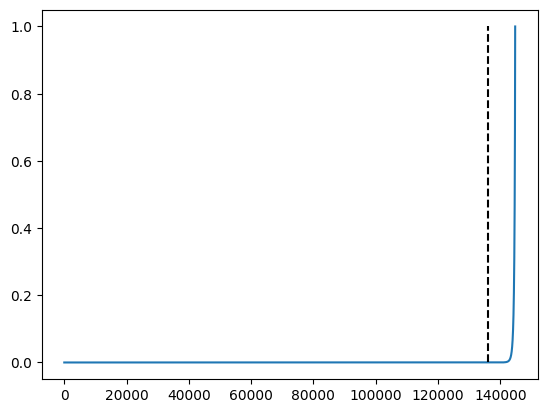

In [ ]:
plt.figure()
plt.plot(t1cumsum)
plt.plot([idx, idx],[0,1], 'k--')

C:\Users\au646858\AppData\Local\Temp\ipykernel_19060\2794321.py:5: RuntimeWarning: divide by zero encountered in log10
  plt.plot(np.log10(torch.abs(fwr.t2t[:7]).T))
C:\Users\au646858\AppData\Local\Temp\ipykernel_19060\2794321.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.plot(np.log10(torch.abs(fwr.t2t[:7]).T))


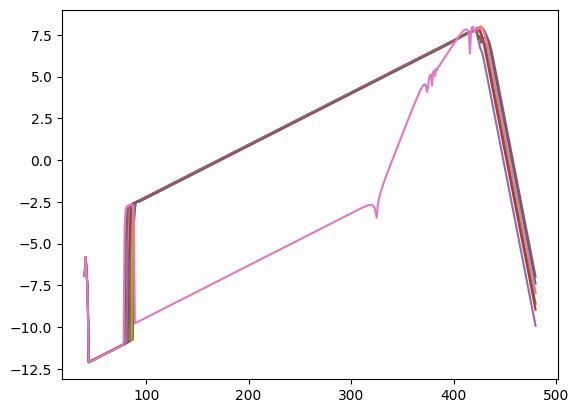

In [ ]:
plt.figure()
plt.plot(np.log10(torch.abs(fwr.t2t[:7]).T))

In [ ]:
ft = invFourier(lambda f: f, device='cpu')
ft1 = invFourier(lambda f:f, tolerance=1e-6)

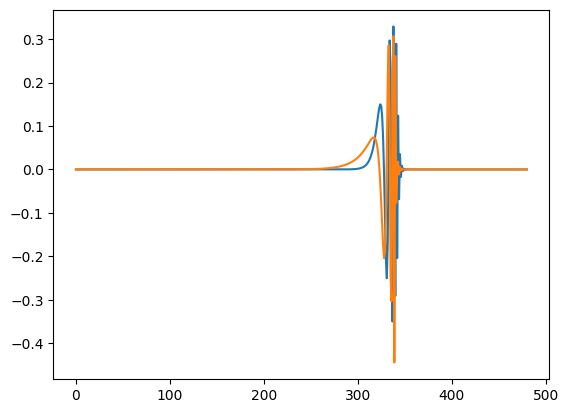

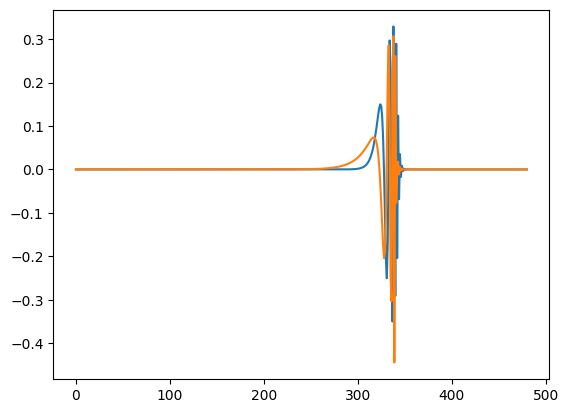

In [ ]:
plt.figure()
plt.plot(ft.fc.imag)
plt.plot(ft.fc.real)

plt.figure()
plt.plot(ft1.fc.imag)
plt.plot(ft1.fc.real)
